# Parte 4 – Evolución temporal de la potencia beta

Serie de potencia beta por época válida (muestreo irregular), periodograma de Lomb y comparación con cubic splines + Welch. Búsqueda del ciclo tarea-pausa (~60 s).

**Por qué Lomb.** Cada época de 2 s da un valor de beta, pero las épocas con artefactos se descartan (Parte 2), así que la serie tiene huecos y deja de estar muestreada cada 2 s. Es el mismo problema que la serie de intervalos RR en HRV: la FFT necesita muestras equiespaciadas. El periodograma de Lomb ajusta, para cada frecuencia, una senoidal por mínimos cuadrados usando solo los instantes donde hay dato. Normalizado, su valor es la fracción de la varianza de la serie que explica una senoidal de esa frecuencia (entre 0 y 1).

**Qué se busca.** La tarea alterna bloques de unos 43 s con pausas de unos 15 s: un ciclo de unos 58 s (≈ 0,017 Hz). Si beta sube en la tarea y baja en la pausa, el periodograma tiene que mostrar un pico en esa frecuencia.

Decisiones (el detalle está en `dinamica.py`):
- la serie es log10 de beta, con la tendencia lineal restada en cada sesión;
- la significación se evalúa por permutación.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from eeg_nback import datos, dinamica
from eeg_nback.config import load_config

cfg = load_config()
OUT = cfg['OUTPUT_DIR']
SEED = cfg['SEED']

F = np.arange(0.002, 0.1, 0.0005)   # Hz: una sesión dura ~960 s (resolución natural ~0,001 Hz), se sobremuestrea ×2
CICLO = 58.0                        # s, valor de referencia para las pruebas sintéticas

## 1. Verificación con series sintéticas

Antes de usar el EEG se prueban las funciones con series de las que se conoce la respuesta. Las series imitan las reales:

- un valor cada 2 s durante 960 s (una sesión);
- log10 de beta = nivel + una senoidal de período 58 s + ruido;
- huecos agrupados, como los de las épocas rechazadas: los artefactos no caen en épocas sueltas sino en rachas (parpadeos seguidos, un movimiento de varios segundos).

La amplitud de la senoidal (0,05 en log10, es decir ±12 %) es chica frente al ruido (desvío 0,1): el ciclo explica solo una parte de la varianza, como se espera en el EEG.

In [3]:
def serie_sintetica(rng, amp=0.05, ruido=0.1, frac_huecos=0.2, deriva=0.0, ciclo=CICLO, dur=960):
    t = np.arange(1, dur, 2.0)
    logb = 1 + amp * np.sin(2 * np.pi * t / ciclo) + deriva * t / dur + ruido * rng.standard_normal(len(t))
    queda = np.ones(len(t), bool)
    while 1 - queda.mean() < frac_huecos:            # rachas de 2 a 15 épocas
        i = rng.integers(0, len(t))
        queda[i:i + rng.integers(2, 16)] = False
    return t[queda], 10 ** logb[queda], t, 10 ** logb

rng = np.random.default_rng(SEED)
t_h, b_h, t_c, b_c = serie_sintetica(rng)
print(f"{len(t_c)} épocas, quedan {len(t_h)} ({len(t_h) / len(t_c) * 100:.0f} %)")

480 épocas, quedan 378 (79 %)


### 1.1 Lomb sin huecos coincide con el periodograma común

Con muestreo uniforme, Lomb tiene que dar lo mismo que el periodograma de la FFT. Se comparan los dos sobre la serie completa (sin huecos).

Pico de Lomb: 0.0170 Hz   ciclo: 0.0172 Hz
Correlación entre Lomb y la FFT en las frecuencias de la FFT: 1.0000


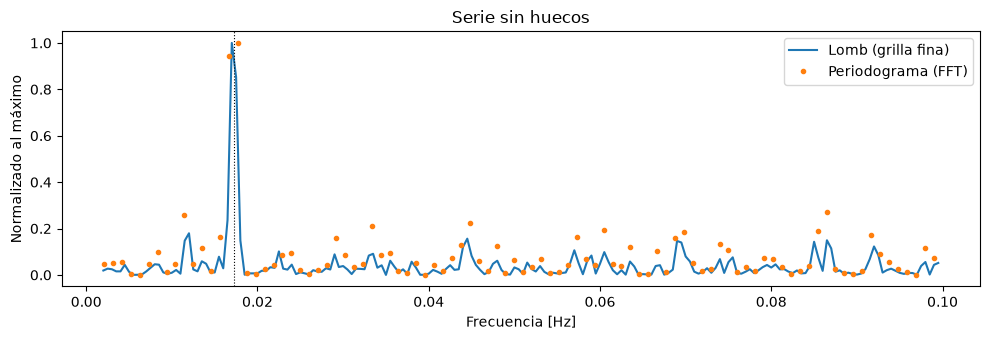

In [4]:
y_c = dinamica.preparar(t_c, b_c)
f_fft, p_fft = signal.periodogram(y_c, fs=0.5, detrend=False)
en_rango = (f_fft >= F[0]) & (f_fft <= F[-1])
f_k = f_fft[en_rango]                        # frecuencias de la FFT (múltiplos de 1/960 Hz)
pg_k = dinamica.lomb(t_c, y_c, f_k)          # Lomb evaluado en esas mismas frecuencias
pg_c = dinamica.lomb(t_c, y_c, F)            # y en la grilla fina, para el gráfico

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(F, pg_c / pg_c.max(), label='Lomb (grilla fina)')
ax.plot(f_k, p_fft[en_rango] / p_fft[en_rango].max(), 'o', ms=3, label='Periodograma (FFT)')
ax.axvline(1 / CICLO, color='k', lw=0.8, ls=':')
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('Normalizado al máximo')
ax.set_title('Serie sin huecos')
ax.legend()
plt.tight_layout()
print(f"Pico de Lomb: {F[pg_c.argmax()]:.4f} Hz   ciclo: {1 / CICLO:.4f} Hz")
print(f"Correlación entre Lomb y la FFT en las frecuencias de la FFT: {np.corrcoef(pg_k, p_fft[en_rango])[0, 1]:.4f}")

### 1.2 Con huecos: Lomb contra cubic splines + Welch

Se aplica cada método a la serie con huecos. La interpolación con splines rellena cada hueco con una curva que pasa por los puntos de los bordes, y en los huecos largos "inventa" oscilaciones lentas que no existen.

Pico de Lomb: 0.0170 Hz   Pico de splines + Welch: 0.0117 Hz


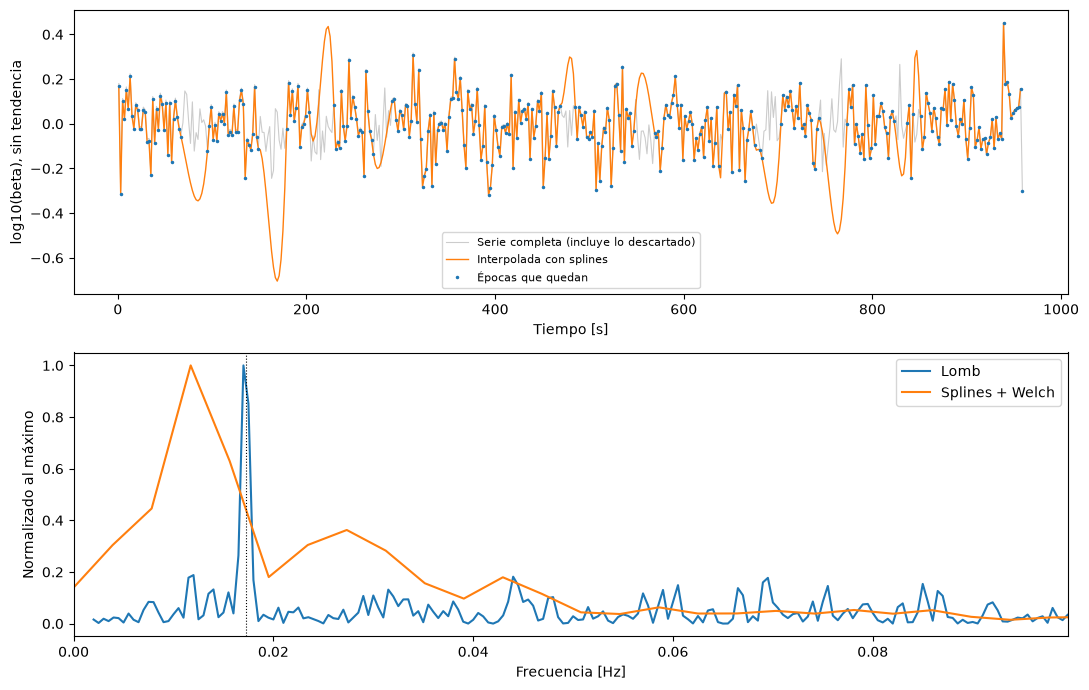

In [5]:
y_h = dinamica.preparar(t_h, b_h)
pg_h = dinamica.lomb(t_h, y_h, F)
f_w, p_w, tu, yu = dinamica.spline_welch(t_h, y_h)

fig, axs = plt.subplots(2, 1, figsize=(11, 7))
axs[0].plot(t_c, y_c, color='0.8', lw=0.8, label='Serie completa (incluye lo descartado)')
axs[0].plot(tu, yu, color='C1', lw=1, label='Interpolada con splines')
axs[0].plot(t_h, y_h, '.', color='C0', ms=3, label='Épocas que quedan')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('log10(beta), sin tendencia')
axs[0].legend(fontsize=8)

axs[1].plot(F, pg_h / pg_h.max(), label='Lomb')
axs[1].plot(f_w, p_w / p_w[f_w <= F[-1]].max(), label='Splines + Welch')
axs[1].axvline(1 / CICLO, color='k', lw=0.8, ls=':')
axs[1].set_xlim(0, F[-1])
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Normalizado al máximo')
axs[1].legend()
plt.tight_layout()
print(f"Pico de Lomb: {F[pg_h.argmax()]:.4f} Hz   Pico de splines + Welch: {f_w[p_w.argmax()]:.4f} Hz")

Una sola serie puede salir bien o mal por azar. Para comparar los métodos se repite con 300 series y se cuenta en cuántas el máximo del espectro cae en el ciclo (± 0,002 Hz, la resolución de Welch). También se mide qué fracción de la potencia entre 0,002 y 0,1 Hz queda por debajo de 0,01 Hz: el ciclo no tiene potencia ahí, así que todo lo que aparece es ruido o lo que agrega la interpolación.

In [6]:
def evaluar_metodos(n=300, **kw):
    rng = np.random.default_rng(SEED)
    filas = []
    for _ in range(n):
        t_h, b_h, _, _ = serie_sintetica(rng, **kw)
        y = dinamica.preparar(t_h, b_h)
        pg = dinamica.lomb(t_h, y, F)
        fw, pw, _, _ = dinamica.spline_welch(t_h, y)
        rango = (fw >= F[0]) & (fw <= F[-1])
        filas.append({
            'lomb_acierta': abs(F[pg.argmax()] - 1 / CICLO) <= 0.002,
            'welch_acierta': abs(fw[rango][pw[rango].argmax()] - 1 / CICLO) <= 0.002,
            'lomb_bajo_001': pg[F < 0.01].sum() / pg.sum(),
            'welch_bajo_001': pw[rango & (fw < 0.01)].sum() / pw[rango].sum(),
        })
    return pd.DataFrame(filas).mean()

res = pd.DataFrame({f'{int(fh * 100)} % de huecos': evaluar_metodos(frac_huecos=fh) for fh in (0.0, 0.2, 0.4)})
res.index = ['Lomb: máximo en el ciclo', 'Splines + Welch: máximo en el ciclo',
             'Lomb: fracción < 0,01 Hz', 'Splines + Welch: fracción < 0,01 Hz']
(res * 100).round(1)

,0 % de huecos,20 % de huecos,40 % de huecos
Lomb: máximo en el ciclo,100.0,99.7,98.0
Splines + Welch: máximo en el ciclo,88.0,22.0,11.0
"Lomb: fracción < 0,01 Hz",6.1,7.3,8.1
"Splines + Welch: fracción < 0,01 Hz",5.4,29.4,41.2


 **Resultado:** 
 - sin huecos, los dos métodos encuentran el ciclo (Lomb en el 100 % de las series, splines + Welch en el 88 %; la diferencia se debe a la resolución de Welch). 
 - Con huecos, splines + Welch empeora mucho: acierta en el 22 % de las series con 20 % de huecos y en el 11 % con 40 %, y la potencia por debajo de 0,01 Hz sube de 5,4 % a 29,4 % y 41,2 %. Lomb casi no cambia (99,7 % y 98,0 % de aciertos; 7,3 % y 8,1 % por debajo de 0,01 Hz). La interpolación rellena los huecos largos con curvas lentas que no existen.

### 1.3 La prueba de permutación no da falsos positivos

Se generan series sin ciclo (amplitud 0) y se calcula el p-valor de cada una en la frecuencia del ciclo. Si la prueba funciona, el p-valor tiene que ser menor que 0,05 en cerca del 5 % de las series. Se prueba también con una deriva lenta (la serie sube 0,2 en log10 a lo largo de la sesión, un 58 %), con y sin restar la tendencia: la deriva pone potencia en las frecuencias más bajas, cerca del ciclo.

In [7]:
def falsos_positivos(n=200, n_perm=200, deriva=0.0, sin_tendencia=True):
    rng = np.random.default_rng(SEED)
    p = []
    for _ in range(n):
        t_h, b_h, _, _ = serie_sintetica(rng, amp=0.0, deriva=deriva)
        y = dinamica.preparar(t_h, b_h, sin_tendencia=sin_tendencia)
        p.append(dinamica.permutacion(t_h, y, F, 1 / CICLO, n_perm, seed=int(rng.integers(1e9)))[0])
    return np.mean(np.array(p) < 0.05) * 100

pd.DataFrame({
    'p < 0,05 [%]': [falsos_positivos(), falsos_positivos(deriva=0.2, sin_tendencia=False),
                     falsos_positivos(deriva=0.2, sin_tendencia=True)],
}, index=['Sin deriva', 'Con deriva, sin restar la tendencia', 'Con deriva, restando la tendencia']).round(1)

,"p < 0,05 [%]"
Sin deriva,5.5
"Con deriva, sin restar la tendencia",11.0
"Con deriva, restando la tendencia",5.5


También se calcula la sensibilidad: con qué frecuencia se detecta el ciclo cuando sí está, según su amplitud.

In [8]:
def sensibilidad(amp, n=200, n_perm=200):
    rng = np.random.default_rng(SEED)
    p = []
    for _ in range(n):
        t_h, b_h, _, _ = serie_sintetica(rng, amp=amp)
        y = dinamica.preparar(t_h, b_h)
        p.append(dinamica.permutacion(t_h, y, F, 1 / CICLO, n_perm, seed=int(rng.integers(1e9)))[0])
    return np.mean(np.array(p) < 0.05) * 100

amps = [0.01, 0.02, 0.03, 0.05]
pd.DataFrame({'cambio tarea-pausa (±%)': [round((10 ** a - 1) * 100, 1) for a in amps],
              'detectado [%]': [sensibilidad(a) for a in amps]}, index=amps).rename_axis('amplitud (log10)')

,cambio tarea-pausa (±%),detectado [%]
amplitud (log10),,
0.01,2.3,18.5
0.02,4.7,64.5
0.03,7.2,94.5
0.05,12.2,100.0


**Resultado:** con una sesión de 16 min y 20 % de huecos, un cambio tarea-pausa de ±4,7 % se detecta en el 64,5 % de las series, uno de ±7,2 % en el 94,5 % y uno de ±12,2 % en todas. Un cambio de ±2,3 % se detecta solo en el 18,5 %. Ese es el límite de lo que la Parte 4 puede ver en una sesión.

## 2. Una serie real

Se usa `outputs/potencias_epocas.csv` (generada por `scripts/generar_potencias.py`), con las épocas `usable_beta`. Se incluyen las pausas: sin ellas no hay contraste con la tarea y el ciclo no se puede ver.

In [9]:
pot = pd.read_csv(OUT / 'potencias_epocas.csv')
sujetos = datos.listar_sujetos()
bloques = pd.concat([datos.tabla_bloques(datos.cargar_nback(s.ruta)).assign(sujeto=s.sujeto)
                     for s in sujetos.itertuples()], ignore_index=True)

validas = pot[pot['usable_beta']]
n_por_serie = validas.groupby(['sujeto', 'sesion', 'canal']).size()
print(f"Series (sujeto, sesión, canal): {len(n_por_serie)}")
print(f"Épocas válidas por serie: mediana {n_por_serie.median():.0f}, mínimo {n_por_serie.min()}, máximo {n_por_serie.max()}")
print(f"Épocas por sesión si no se rechazara ninguna: ~{pot.groupby(['sujeto', 'sesion', 'canal']).size().median():.0f}")

Series (sujeto, sesión, canal): 263
Épocas válidas por serie: mediana 422, mínimo 5, máximo 457
Épocas por sesión si no se rechazara ninguna: ~451


Ciclo medido: 59.3 s (0.0169 Hz). Lomb en el ciclo: 0.003, p = 0.671


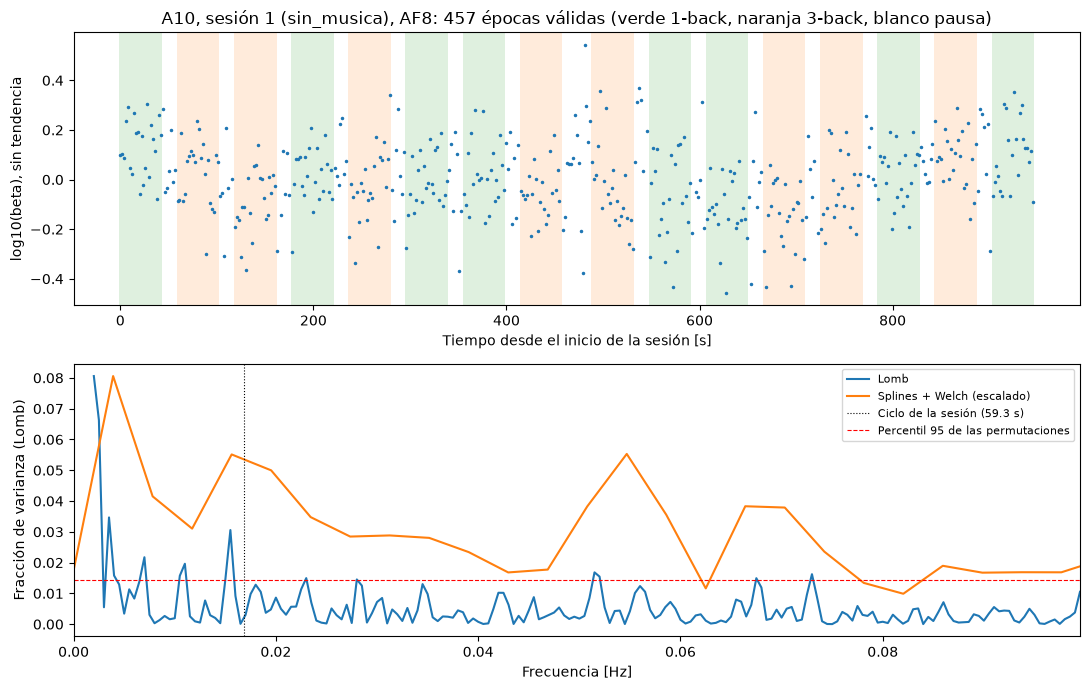

In [10]:
# Ejemplo: la serie con más épocas válidas (se puede cambiar por cualquier sujeto, sesión y canal)
SUJ, SES, CANAL = n_por_serie.idxmax()
g = validas[(validas.sujeto == SUJ) & (validas.sesion == SES) & (validas.canal == CANAL)].sort_values('t_centro')
b = bloques[(bloques.sujeto == SUJ) & (bloques.sesion == SES)]
t0 = g.t_centro.min()
t, y = dinamica.serie_beta(g.t_centro, g.beta, np.ones(len(g), bool))
y = dinamica.preparar(t, y)
f0 = dinamica.frecuencia_ciclo(b)

fig, axs = plt.subplots(2, 1, figsize=(11, 7))
for r in b.itertuples():
    axs[0].axvspan(r.t_ini - t0, r.t_fin - t0, color='C1' if r.tipo == '3-back' else 'C2', alpha=0.15, lw=0)
axs[0].plot(t, y, '.', ms=3)
axs[0].set_xlabel('Tiempo desde el inicio de la sesión [s]')
axs[0].set_ylabel('log10(beta), sin tendencia')
axs[0].set_title(f'{SUJ}, sesión {SES} ({g.condicion.iloc[0]}), {CANAL}: {len(g)} épocas válidas '
                 '(verde 1-back, naranja 3-back, blanco pausa)')

pg = dinamica.lomb(t, y, F)
fw, pw, _, _ = dinamica.spline_welch(t, y)
p, nulo = dinamica.permutacion(t, y, F, f0, n_perm=500, seed=SEED)
axs[1].plot(F, pg, label='Lomb')
axs[1].plot(fw, pw / pw[(fw >= F[0]) & (fw <= F[-1])].max() * pg.max(), label='Splines + Welch (escalado)')
axs[1].axvline(f0, color='k', lw=0.8, ls=':', label=f'Ciclo de la sesión ({1 / f0:.1f} s)')
axs[1].axhline(np.quantile(nulo, 0.95), color='r', lw=0.8, ls='--', label='Percentil 95 de las permutaciones')
axs[1].set_xlim(0, F[-1])
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Fracción de varianza (Lomb)')
axs[1].legend(fontsize=8)
plt.tight_layout()
print(f"Ciclo medido: {1 / f0:.1f} s ({f0:.4f} Hz). Lomb en el ciclo: {dinamica.potencia_en(F, pg, f0):.3f}, p = {p:.3f}")

 **Resultado:** en esta serie (la de más épocas válidas, con un ciclo medido de 59,3 s) no hay pico en el ciclo: Lomb explica el 0,3 % de la varianza en esa frecuencia y p = 0,67. Es una sola serie; la sección 3 muestra que en la mayoría el ciclo sí aparece.

## 3. Todas las series

Se analizan todas las series (sujeto, sesión y canal) con al menos 200 épocas válidas: con menos, los huecos ocupan más de la mitad de la sesión. Con 500 permutaciones por serie tarda unos minutos.

In [11]:
res = dinamica.analizar_sesiones(pot, bloques, F, min_epocas=200, n_perm=500, seed=SEED)
res.to_csv(OUT / 'lomb_series.csv', index=False)
print(f"{len(res)} series analizadas de {len(n_por_serie)}")
print(f"Ciclo medido: mediana {1 / res.f_ciclo.median():.1f} s, rango {1 / res.f_ciclo.max():.1f} a {1 / res.f_ciclo.min():.1f} s")

257 series analizadas de 263
Ciclo medido: mediana 58.9 s, rango 55.9 a 59.3 s


In [12]:
from scipy import stats

resumen = res.groupby('canal').agg(
    series=('p_valor', 'size'),
    sujetos=('sujeto', 'nunique'),
    pct_p_menor_005=('p_valor', lambda p: (p < 0.05).mean() * 100),
    pct_maximo_en_ciclo=('es_pico_ciclo', lambda x: x.mean() * 100),
    varianza_en_ciclo_mediana=('p_ciclo', 'median'),
)
# ¿Hay más series significativas que el 5 % esperado por azar? Prueba binomial por canal
resumen['p_binomial'] = [stats.binomtest(int((g.p_valor < 0.05).sum()), len(g), 0.05, alternative='greater').pvalue
                         for _, g in res.groupby('canal')]
resumen.round(3)

,series,sujetos,pct_p_menor_005,pct_maximo_en_ciclo,varianza_en_ciclo_mediana,p_binomial
canal,,,,,,
AF7,60,17,53.333,8.333,0.019,0.0
AF8,66,19,53.030,12.121,0.017,0.0
TP10,65,19,80.000,35.385,0.049,0.0
TP9,66,19,77.273,36.364,0.056,0.0


**Cómo leer la tabla.** Si beta no siguiera el ciclo, cerca del 5 % de las series darían p < 0,05 por azar. La prueba binomial dice si la proporción observada es mayor que eso. Se informa por canal porque los frontales y los temporales tienen distinta calidad (Parte 2). Las series de un mismo sujeto no son independientes entre sí (comparten sujeto y a veces sesión), así que la binomial es orientativa: el número de sujetos con al menos una serie significativa es más conservador.

In [13]:
por_sujeto = res.groupby(['experimento', 'sujeto']).agg(series=('p_valor', 'size'),
                                                         significativas=('p_valor', lambda p: int((p < 0.05).sum())))
print(f"Sujetos con al menos una serie significativa: {(por_sujeto.significativas > 0).sum()} de {len(por_sujeto)}")
por_sujeto.T

Sujetos con al menos una serie significativa: 20 de 20


experimento      1                                     2                     \
sujeto          A1 A10  A2  A3  A4  A5  A6  A7  A8 A9 B1 B10  B2  B3  B4 B5   
series          16  16  16  16  12  16  16  14  16  8  6  12  12  12  12  9   
significativas   8  10  11   9  12  11  11  11   8  8  5   8  12   4   4  5   

experimento                     
sujeto          B6  B7  B8  B9  
series          12  12  12  12  
significativas   7   6  10  10

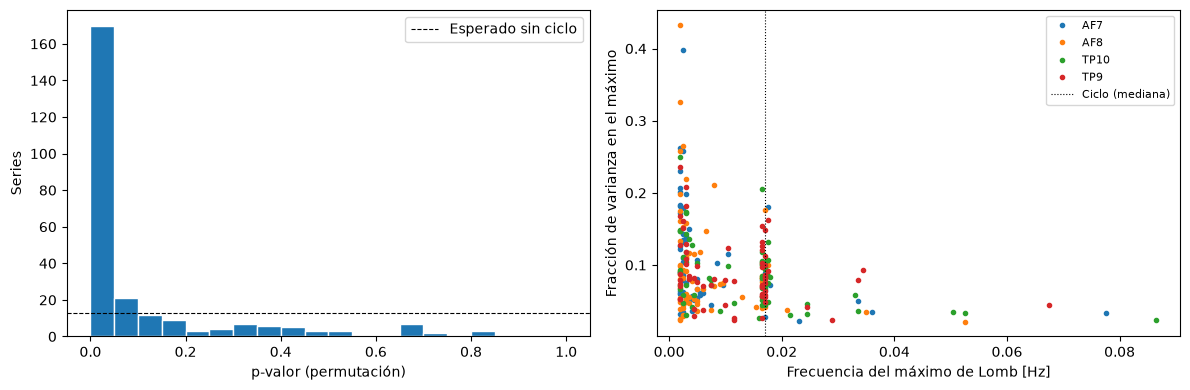

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(res.p_valor, bins=20, range=(0, 1), edgecolor='w')
axs[0].axhline(len(res) / 20, color='k', ls='--', lw=0.8, label='Esperado sin ciclo')
axs[0].set_xlabel('p-valor (permutación)')
axs[0].set_ylabel('Series')
axs[0].legend()

for c, g in res.groupby('canal'):
    axs[1].plot(g.f_pico, g.p_pico, '.', label=c)
axs[1].axvline(res.f_ciclo.median(), color='k', ls=':', lw=0.8, label='Ciclo (mediana)')
axs[1].set_xlabel('Frecuencia del máximo de Lomb [Hz]')
axs[1].set_ylabel('Fracción de varianza en el máximo')
axs[1].legend(fontsize=8)
plt.tight_layout()

## 4. ¿En qué sentido cambia beta?

El periodograma dice si hay un ciclo, pero no si beta es mayor en la tarea o en la pausa: una senoidal tiene la misma potencia con cualquier fase. Se mira directamente el cociente entre la mediana de beta en la tarea y en la pausa de cada serie. La prueba estadística de esta diferencia es de la Parte 5 (tarea contra pausa con Wilcoxon); acá solo se usa para interpretar los picos.

In [15]:
tp = (validas.assign(fase=np.where(validas.tipo == 'pausa', 'pausa', 'tarea'))
      .groupby(['sujeto', 'sesion', 'canal', 'fase']).beta.median().unstack('fase'))
tp['cociente'] = tp['tarea'] / tp['pausa']
res2 = res.merge(tp['cociente'].reset_index(), on=['sujeto', 'sesion', 'canal'])
res2['significativa'] = res2.p_valor < 0.05
res2.groupby(['canal', 'significativa']).cociente.agg(['size', 'median']).round(3)

size  median
canal significativa              
AF7   False            28   0.969
      True             32   0.910
AF8   False            31   0.993
      True             35   1.007
TP10  False            13   1.000
      True             52   0.808
TP9   False            15   0.950
      True             51   0.801

### 4.1 ¿Cuánto influyen las deflexiones?

La Parte 3 mostró que las épocas con deflexión tienen más beta en TP9 y TP10 (×1,15 y ×1,21), y que su proporción no cambia entre 1-back y 3-back. Falta ver si cambia entre tarea y pausa: si en la pausa hay más deflexiones, o deflexiones con más beta, el cociente tarea/pausa baja aunque la actividad cerebral no cambie. Se repite el cociente usando solo las épocas sin deflexión (las que pasan también el rechazo de 1 a 40 Hz), en los sujetos con al menos 20 de esas épocas en la tarea y en la pausa.

In [16]:
v = validas.assign(fase=np.where(validas.tipo == 'pausa', 'pausa', 'tarea'), deflexion=~validas.usable)
print('% de épocas con deflexión (no pasan el rechazo de 1 a 40 Hz):')
print((v.groupby(['canal', 'fase']).deflexion.mean().unstack() * 100).round(1))

s = v.groupby(['sujeto', 'canal', 'fase']).beta.median().unstack('fase')
todas = (s.tarea / s.pausa).groupby('canal').agg(['size', 'median'])

s = v[~v.deflexion].groupby(['sujeto', 'canal', 'fase']).beta.agg(['median', 'size']).unstack('fase')
s = s[(s[('size', 'pausa')] >= 20) & (s[('size', 'tarea')] >= 20)]
limpias = (s[('median', 'tarea')] / s[('median', 'pausa')]).groupby('canal').agg(['size', 'median'])

pd.concat({'todas las épocas usable_beta': todas, 'solo sin deflexión': limpias}, axis=1).round(3)

% de épocas con deflexión (no pasan el rechazo de 1 a 40 Hz):
fase   pausa  tarea
canal              
AF7     27.4   22.8
AF8     27.2   14.4
TP10    78.5   75.3
TP9     77.8   76.1


todas las épocas usable_beta        solo sin deflexión       
                              size median               size median
canal                                                              
AF7                             17  0.947                 17  0.994
AF8                             19  1.029                 19  1.029
TP10                            20  0.840                 16  0.936
TP9                             19  0.801                 15  0.910

## 5. Conclusiones

1. **Verificación.** Sin huecos, Lomb coincide con el periodograma de la FFT (correlación 1,0000). La prueba de permutación da 5,5 % de falsos positivos en series sin ciclo (se espera 5 %). Con una deriva lenta, si no se resta la tendencia los falsos positivos suben a 11,0 %; restándola vuelven a 5,5 %.
2. **Lomb frente a splines + Welch.** Con 20 % de huecos agrupados, Lomb encuentra el ciclo en el 99,7 % de las series y splines + Welch en el 22 %, porque la interpolación agrega potencia por debajo de 0,01 Hz (29,4 % del total, contra 7,3 % con Lomb).
3. **Sensibilidad.** En una sesión se detecta un cambio tarea-pausa de ±7 % en el 94,5 % de las series, y uno de ±2 % en el 18,5 %.
4. **El ciclo tarea-pausa está en el EEG.** Se analizaron 257 de las 263 series (las otras 6 tienen menos de 200 épocas válidas). En la frecuencia del ciclo (mediana 58,9 s) dan p < 0,05 el 53 % de las series de AF7 y AF8 y el 77-80 % de las de TP9 y TP10, contra un 5 % esperado por azar (prueba binomial, p < 0,001 en los cuatro canales). Los 20 sujetos tienen al menos una serie significativa. El ciclo explica una parte chica de la varianza (mediana 1,7-1,9 % en los frontales y 4,9-5,6 % en los temporales) y no siempre es la frecuencia dominante: es el máximo del periodograma en el 8-36 % de las series, porque quedan variaciones más lentas que la tendencia lineal no saca.
5. **El sentido es el contrario al esperado.** En las series significativas de TP9 y TP10, la mediana de beta en la tarea es un 20 % menor que en la pausa (cocientes 0,80 y 0,81). En los frontales casi no cambia (0,91 en AF7 y 1,01 en AF8).
6. **Parte de la diferencia está ligada a las deflexiones (sección 4.1).** En los frontales hay más épocas con deflexión en la pausa que en la tarea (AF8: 27,2 % contra 14,4 %; AF7: 27,4 % contra 22,8 %), compatible con que se parpadea más fuera de la tarea. En TP9 y TP10 la proporción es casi igual (77,8-78,5 % contra 75,3-76,1 %), pero las épocas con deflexión de la pausa aportan más beta: con solo las épocas sin deflexión, el cociente tarea/pausa pasa de 0,80 a 0,91 en TP9 y de 0,84 a 0,94 en TP10, y en los frontales queda cerca de 1 (0,99 y 1,03). Esa comparación usa menos sujetos (15 y 16 en los temporales), porque varios no tienen 20 épocas sin deflexión en cada fase.
7. **Interpretación.** Hay dos explicaciones posibles, que no se excluyen: artefactos en la pausa (parpadeos, mandíbula y movimiento, cerca de TP9 y TP10) y una disminución real de beta durante la tarea, asociada a apretar un botón cada 2 s. Con 4 canales y sin EOG ni EMG no se pueden separar. Lo que se puede afirmar es que, en épocas limpias, beta no sube en la tarea: en los temporales baja un 6-9 % y en los frontales no cambia. La Parte 5 prueba la diferencia tarea-pausa con Wilcoxon.